# Introduction to Probabilistic Methods

*Monte Carlo* algorithms are randomized algorithms whose runtime is deterministic (or strictly bounded), but whose output may vary across runs and carries an approximation or failure probability. *Las Vegas* algorithms always return a correct answer, but their runtime is a random variable.

## Buffon's Needle (1733, 1777)

[See here for a complete treatment on Wikipedia](https://en.wikipedia.org/wiki/Buffon%27s_needle_problem)

Suppose a floor consists of parallel stripes of width $d$, and a needle of length $l \le d$ is dropped at random. What is the probability of the needle crossing a stripe boundary?

![Buffon's needle experiment setup](data/buffon.jpg)

Due to translational and reflexive symmetry, the position of the needle can be parameterized by two independent uniform random variables:
- The distance $x$ from the needle's center to the nearest boundary: $x \in [0, d/2]$
- The acute angle $\theta$ relative to the stripe direction: $\theta \in [0, \pi / 2]$

The total area of the parameter space is $(d/2) \cdot (\pi/2) = \frac{\pi d}{4}$.

A needle at angle $\theta$ crosses a boundary if and only if $x \le \frac{l}{2} \sin \theta$. Therefore, the crossing probability $p$ is:

$$p = \frac{\int_{0}^{\pi/2} \int_{0}^{\frac{l}{2} \sin \theta} dx \, d\theta}{\frac{\pi d}{4}} = \frac{\frac{l}{2} \int_{0}^{\pi/2} \sin \theta \, d\theta}{\frac{\pi d}{4}} = \frac{2l}{\pi d}.$$

Rearranging gives $\pi = \frac{2l}{pd}$, allowing $\pi$ to be estimated empirically by replacing $p$ with the observed crossing frequency.

*What drawbacks does this scheme have when simulated on a computer?*

---

## "Darts"

*Propose a Monte Carlo scheme for estimating $\pi$ based on it being the area of a unit circle.*

---

## Rate of Convergence

Let $I_i \sim \operatorname{Bernoulli}(p)$ be the indicator variable of the $i$-th trial crossing the line ($I_i = 1$ if crossing, $0$ otherwise) or hitting the circle.

- Expected value: $\mathbb{E}[I_i] = p$
- Variance: $\operatorname{Var}(I_i) = \sigma^2 = p(1-p)$

For $N$ independent trials, the sample proportion is $\hat{p} = \frac{1}{N} \sum_{i=1}^N I_i$.

Because the trials are independent:
$$\operatorname{Var}(\hat{p}) = \frac{1}{N^2} \sum_{i=1}^N \operatorname{Var}(I_i) = \frac{N \sigma^2}{N^2} = \frac{\sigma^2}{N}.$$

Because $\mathbb{E}[\hat{p}] = p$, the estimator is unbiased (expected signed error is $0$). By the Central Limit Theorem, the estimation error $(\hat{p} - p)$ converges in distribution to $\mathcal{N}(0, \sigma^2 / N)$.

The standard error (Root Mean Squared Error) is:
$$\operatorname{RMSE} = \sqrt{\operatorname{Var}(\hat{p})} = \frac{\sigma}{\sqrt{N}} = O(N^{-1/2}).$$

This convergence rate of $O(N^{-1/2})$ is low: reducing the error by a factor of $10$ (to gain one additional decimal digit of precision) requires a $100\times$ increase in sample size $N$.

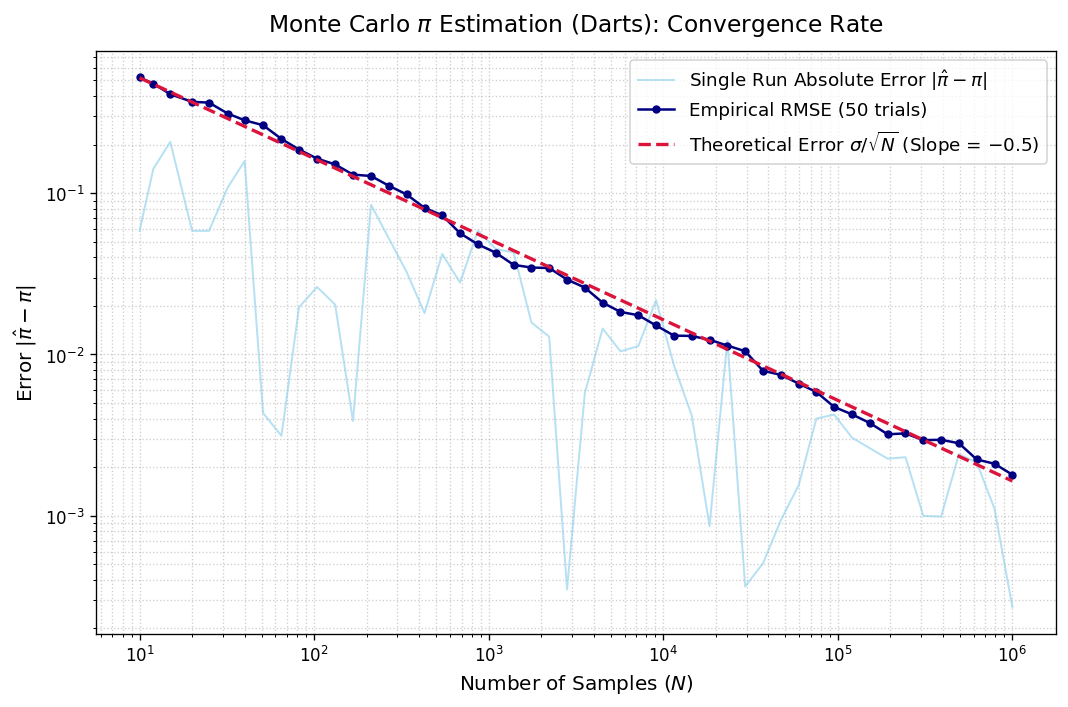

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Parameters
# ---------------------------------------------------------
np.random.seed(42)
max_samples = 10**6
num_trials = 50  # Repeat across multiple runs to estimate empirical RMSE

# Checkpoints for N along a logarithmic grid
n_checkpoints = np.logspace(1, 6, num=50, dtype=int)
n_checkpoints = np.unique(n_checkpoints)  # Deduplicate

# ---------------------------------------------------------
# Simulation
# ---------------------------------------------------------
all_estimates = np.zeros((num_trials, len(n_checkpoints)))

for t in range(num_trials):
    # Sample uniformly from the unit square [0, 1] x [0, 1]
    # (quarter circle of radius 1 inside unit square of area 1)
    x = np.random.uniform(0.0, 1.0, size=max_samples)
    y = np.random.uniform(0.0, 1.0, size=max_samples)
    
    # Check if point falls inside unit circle (quarter area = pi / 4)
    hits = (x**2 + y**2 <= 1.0)
    
    # Cumulative hits up to each index
    cum_hits = np.cumsum(hits)
    
    # Estimate pi = 4 * (hits / N)
    all_estimates[t, :] = 4.0 * cum_hits[n_checkpoints - 1] / n_checkpoints

# ---------------------------------------------------------
# Error Calculations
# ---------------------------------------------------------
# Absolute error for a single representative run
single_run_error = np.abs(all_estimates[0, :] - np.pi)

# Empirical RMSE across all trials: sqrt( E[ (pi_hat - pi)^2 ] )
rmse_empirical = np.sqrt(np.mean((all_estimates - np.pi)**2, axis=0))

# Theoretical Standard Error:
# p = pi / 4, Var(I) = p(1 - p)
# pi_hat = 4 * p_hat  =>  Var(pi_hat) = 16 * Var(p_hat) = 16 * p(1 - p) / N
p = np.pi / 4.0
theoretical_sigma = 4.0 * np.sqrt(p * (1.0 - p))
theoretical_rmse = theoretical_sigma / np.sqrt(n_checkpoints)

# ---------------------------------------------------------
# Plotting (Log-Log Scale)
# ---------------------------------------------------------
plt.figure(figsize=(9, 6), dpi=120)

# Single realization (noisy)
plt.loglog(
    n_checkpoints, single_run_error,
    color="skyblue", alpha=0.6, linewidth=1.2,
    label="Single Run Absolute Error $|\hat{\pi} - \pi|$"
)

# Empirical average RMSE across 50 runs
plt.loglog(
    n_checkpoints, rmse_empirical,
    "o-", color="navy", markersize=4, linewidth=1.5,
    label=f"Empirical RMSE ({num_trials} trials)"
)

# Theoretical 1/sqrt(N) curve (slope = -0.5)
plt.loglog(
    n_checkpoints, theoretical_rmse,
    "--", color="crimson", linewidth=2.0,
    label=r"Theoretical Error $\sigma / \sqrt{N}$ (Slope = $-0.5$)"
)

plt.title(r"Monte Carlo $\pi$ Estimation (Darts): Convergence Rate", fontsize=14, pad=12)
plt.xlabel(r"Number of Samples ($N$)", fontsize=12)
plt.ylabel(r"Error $|\hat{\pi} - \pi|$", fontsize=12)
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()

plt.show()

## Curse of Dimensionality

Evaluating a 1D integral—such as the area under a curve—can be done far more efficiently using standard numerical quadrature (e.g., Simpson's rule or Gaussian quadrature) than by Monte Carlo sampling. 

However, suppose our task is to compute the volume or mass of a $d$-dimensional body. If we apply a deterministic grid-based method with $m$ evaluation points along each axis, the total number of function evaluations is $N = m^d$. Halving the grid spacing requires $2m$ points per dimension, increasing the total evaluations to $(2m)^d = 2^d N$—an exponential explosion that quickly becomes computationally intractable.

In terms of the total sample count $N$:
- A deterministic grid rule typically converges at a rate of $O(N^{-r/d})$, where $r$ is the smoothness of the integrand (depending on the integration rule). As the dimension $d$ grows, this rate rapidly collapses toward zero.
- In contrast, the standard Monte Carlo convergence rate is **$O(N^{-1/2})$, independent of the dimension $d$**.

Consequently, while deterministic methods easily outperform Monte Carlo in 1D or 2D, Monte Carlo becomes the only feasible approach for high-dimensional integration.

In [7]:
import numpy as np
from scipy.special import gamma

def exact_sphere_volume(d: int, r: float = 1.0) -> float:
    """Analytical volume of a d-dimensional sphere of radius r."""
    return (np.pi ** (d / 2.0) / gamma(d / 2.0 + 1.0)) * (r ** d)

# ----------------------------------------------------------------------
# Hypercube Rejection Sampling
# ----------------------------------------------------------------------
def mc_volume_rejection(d: int, r: float = 1.0, n_samples: int = 1_000_000) -> tuple[float, float, float]:
    """Uniform sampling in [-r, r]^d. Fails for d >= 12 due to near-zero hit count."""
    pts = np.random.uniform(-r, r, size=(n_samples, d))
    inside = np.sum(pts**2, axis=1) <= (r**2)
    hits = np.count_nonzero(inside)
    
    v_cube = (2.0 * r) ** d
    p_hat = hits / n_samples
    volume_est = v_cube * p_hat
    std_err = v_cube * np.sqrt(p_hat * (1.0 - p_hat) / n_samples) if hits > 0 else 0.0
    
    return volume_est, std_err, p_hat

# ----------------------------------------------------------------------
# Comparison Benchmark
# ----------------------------------------------------------------------
if __name__ == "__main__":
    np.random.seed(42)
    N = 1_000_000
    r = 1.0

    header = (
        f"{'d':<3} | {'Exact Vol.':<11} | "
        f"{'Rejection':<11} | {'Rej. Error.':<11} | {'Rej. Hit%':<9}"
    )
    print(header)
    print("-" * len(header))

    for d in [2, 3, 5, 8, 10, 14]:
        v_exact = exact_sphere_volume(d, r)
        v_rej, err_rej, p_hit = mc_volume_rejection(d, r, n_samples=N)

        print(
            f"{d:<3} | {v_exact:<11.5f} | "
            f"{v_rej:<11.5f} | {err_rej:<11.5f} | {100.0 * p_hit:<8.4f}% | "
        )

d   | Exact Vol.  | Rejection   | Rej. Error. | Rej. Hit%
---------------------------------------------------------
2   | 3.14159     | 3.14195     | 0.00164     | 78.5488 % | 
3   | 4.18879     | 4.18909     | 0.00400     | 52.3636 % | 
5   | 5.26379     | 5.24605     | 0.01185     | 16.3939 % | 
8   | 4.05871     | 4.04966     | 0.03194     | 1.5819  % | 
10  | 2.55016     | 2.55386     | 0.05107     | 0.2494  % | 
14  | 0.59926     | 0.67174     | 0.10491     | 0.0041  % | 


## Rejection Sampling

The geometric intuition behind "darts" extends naturally to sampling from an arbitrary distribution whose probability density function (PDF) is only known up to a (often intractable) normalizing constant, $p(x) \propto f(x)$.

To sample from $p(x)$:
1. Choose a proposal distribution with density $g(x)$ that is easy to sample from and covers the support of $f$ (so $g(x) > 0$ whenever $f(x) > 0$).
2. Find an envelope constant $M < \infty$ such that $M g(x) \ge f(x)$ for all $x$. Geometrically, this scales the graph of $g(x)$ so that it completely encloses $f(x)$ from above.

Sampling from $p(x)$ reduces to sampling uniformly from the region under the scaled curve $M g(x)$ and discarding points that fall outside the area under $f(x)$:
1. Draw a proposal $x \sim g(x)$.
2. Draw a vertical height $y \sim \operatorname{Uniform}(0, M g(x))$ (equivalently, draw $u \sim \operatorname{Uniform}(0, 1)$ and check if $u \le \frac{f(x)}{M g(x)}$).
3. **Accept** $x$ if $y \le f(x)$; otherwise, **reject** it and repeat.

The overall acceptance probability per trial is:
$$\mathbb{P}(\text{accept}) = \frac{\int f(x) \, dx}{M}.$$

If $f$ is already a normalized density ($\int f(x) \, dx = 1$), the acceptance rate is simply $1/M$. Consequently, $M$ is typically chosen as tight as possible, $M = \sup_x \frac{f(x)}{g(x)}$, to minimize wasteful rejections.

![Rejection sampling illustration](data/rejection.jpg)

Note that rejection sampling also is a Las Vegas algorithm because producing a sample may require an unpredictable number of rejection steps.

## Discrete Diffusion

Consider a process in which a particle moves across discrete time steps, each time by the same distance but a uniformly random sign:

$$\Delta x_t = \{-dx, +dx\}.$$

This process is tightly connected to the heat equation $u_t = Du_{xx}$ considered before. We shall directly simulate it for 20,000 trajectories, observing the emergent aggregate properties.

Final Step Statistics (t = 1000s):
  Ensemble Mean <x>:     0.1440 (Expected: 0.0)
  Ensemble MSD <x^2>:   991.76 (Expected: 1000.00)
  Estimated D:           0.4959 (Expected: 0.5000)


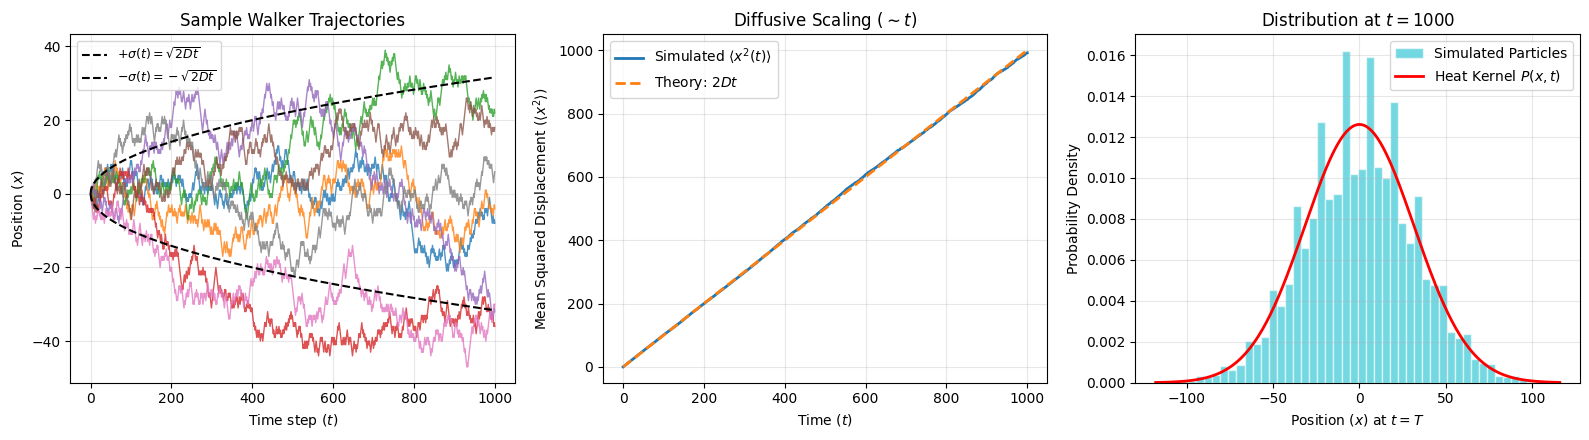

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. Simulation Parameters
# ==============================================================================
n_walkers = 20_000   # Ensemble size (M)
n_steps = 1_000      # Time steps (T)
dt = 1.0             # Time step size (seconds)
dx = 1.0             # Spatial step magnitude (+/- dx)
seed = 4242

rng = np.random.default_rng(seed)

# ==============================================================================
# 2. Vectorized 1D Random Walk
# ==============================================================================
# Generate step increments: each walker independently steps +dx or -dx with p = 0.5
# Shape: (n_walkers, n_steps)
steps = rng.choice([-dx, dx], size=(n_walkers, n_steps))

# Cumulative sum along the time axis gives position at each time step
# Prepend x = 0 at t = 0 so all walkers start at the origin
positions = np.zeros((n_walkers, n_steps + 1))
positions[:, 1:] = np.cumsum(steps, axis=1)

time_array = np.arange(n_steps + 1) * dt

# ==============================================================================
# 3. Statistical Analysis: Mean & Mean Squared Displacement (MSD)
# ==============================================================================
# Theoretical diffusion coefficient for discrete symmetric walk: D = (dx^2) / (2 * dt)
D_theory = (dx**2) / (2 * dt)

# Ensemble averages across all walkers (axis=0)
mean_x = np.mean(positions, axis=0)
msd = np.mean(positions**2, axis=0)
msd_theory = 2 * D_theory * time_array

print(f"Final Step Statistics (t = {time_array[-1]:.0f}s):")
print(f"  Ensemble Mean <x>:     {mean_x[-1]:.4f} (Expected: 0.0)")
print(f"  Ensemble MSD <x^2>:   {msd[-1]:.2f} (Expected: {msd_theory[-1]:.2f})")
print(f"  Estimated D:           {msd[-1] / (2 * time_array[-1]):.4f} (Expected: {D_theory:.4f})")

# ==============================================================================
# 4. Visualizations
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# --- Subplot 1: Representative Trajectories ---
ax1 = axes[0]
n_sample_paths = 8
for i in range(n_sample_paths):
    ax1.plot(time_array, positions[i], lw=1, alpha=0.8)
ax1.plot(time_array, np.sqrt(msd_theory), "k--", lw=1.5, label=r"$+\sigma(t) = \sqrt{2Dt}$")
ax1.plot(time_array, -np.sqrt(msd_theory), "k--", lw=1.5, label=r"$-\sigma(t) = -\sqrt{2Dt}$")
ax1.set_xlabel("Time step ($t$)")
ax1.set_ylabel("Position ($x$)")
ax1.set_title("Sample Walker Trajectories")
ax1.legend(loc="upper left", fontsize=9)
ax1.grid(True, alpha=0.3)

# --- Subplot 2: Mean Squared Displacement (MSD) Scaling ---
ax2 = axes[1]
ax2.plot(time_array, msd, label="Simulated $\\langle x^2(t) \\rangle$", color="tab:blue", lw=2)
ax2.plot(time_array, msd_theory, "--", label="Theory: $2Dt$", color="tab:orange", lw=2)
ax2.set_xlabel("Time ($t$)")
ax2.set_ylabel("Mean Squared Displacement ($\\langle x^2 \\rangle$)")
ax2.set_title("Diffusive Scaling ($\sim t$)")
ax2.legend(loc="upper left")
ax2.grid(True, alpha=0.3)

# --- Subplot 3: Final State vs. Heat Equation Kernel ---
ax3 = axes[2]
final_positions = positions[:, -1]
final_time = time_array[-1]

# Empirical histogram
counts, bin_edges, _ = ax3.hist(
    final_positions, bins=50, density=True, alpha=0.6, color="tab:cyan", edgecolor="white", label="Simulated Particles"
)

# Analytical fundamental solution to heat equation: u(x, t) = (1 / sqrt(4 * pi * D * t)) * exp(-x^2 / (4 * D * t))
x_grid = np.linspace(final_positions.min(), final_positions.max(), 300)
gaussian_pde = (1.0 / np.sqrt(4 * np.pi * D_theory * final_time)) * np.exp(-x_grid**2 / (4 * D_theory * final_time))

ax3.plot(x_grid, gaussian_pde, "r-", lw=2, label="Heat Kernel $P(x, t)$")
ax3.set_xlabel("Position ($x$) at $t = T$")
ax3.set_ylabel("Probability Density")
ax3.set_title(f"Distribution at $t = {int(final_time)}$")
ax3.legend(loc="upper right")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Using bootstrapping for confidence interval estimation

### The Essence of the Bootstrap: "Pulling Yourself Up by Your Own Bootstraps"

In traditional statistics, finding the uncertainty (confidence interval or standard error) of an estimator requires deriving its sampling distribution mathematically. For a simple arithmetic mean of Gaussian data, that is easy. For complex, nonlinear statistics, like our diffusion coefficient $\hat{D}$ derived from squared particle displacements, analytical error propagation can quickly become tedious or analytically impossible.

The [bootstrap](https://en.wikipedia.org/wiki/Bootstrapping_(statistics)) solves this computationally by exploiting a simple insight known as the **Plug-in Principle**:

> **If your sample is representative of the true population, resampling from your sample mimics drawing new samples from reality.**

```
True Reality / Process ────(Collect Data)────► Observed Sample (M walkers)
                                                           │
                                               Resample with replacement
                                                           ▼
                                              Bootstrap Replicate 1 ──► D̂₁*
                                              Bootstrap Replicate 2 ──► D̂₂*
                                                          ...
                                              Bootstrap Replicate B ──► D̂_B*
                                                           │
                                                           ▼
                                               Empirical Distribution of D̂
                                               ↳ Standard Error & 95% CI

```

#### Why "With Replacement"?

If you draw $M$ items from a dataset of size $M$ *without* replacement, you merely shuffle the original data and obtain the exact same statistic every single time. Sampling **with replacement** means each item has a chance of being selected zero, one, or multiple times. This introduces the exact degree of finite-sample variability you would see if you ran the real-world experiment over and over again.

#### In Our Code

Each of our $M = 20{,}000$ simulated walkers travels independently. Rather than running millions of new random walks or deriving $\chi^2$ variance formulas for $x^2(T)$, we treat our simulated walkers as the data pool. By repeatedly drawing batches of $M$ walkers from that pool and recomputing $\hat{D} = \langle x^2 \rangle / (2T)$, the spread of those bootstrap replicates gives us an empirical standard error and confidence interval straight from the data.

In [9]:
# Extract the ensemble of final squared displacements
x_final_sq = positions[:, -1] ** 2   # Shape: (n_walkers,)
T_final = time_array[-1]

# Bootstrap parameters
n_boot = 2_000
alpha = 0.05

# Resample walkers with replacement: shape (n_boot, n_walkers)
boot_indices = rng.choice(n_walkers, size=(n_boot, n_walkers), replace=True)
boot_samples = x_final_sq[boot_indices]

# Compute statistic for each bootstrap replicate: D_hat = mean(x^2) / (2 * T)
boot_D = np.mean(boot_samples, axis=1) / (2 * T_final)

# Compute 95% Percentile Confidence Interval
ci_lower = np.percentile(boot_D, 100 * (alpha / 2))
ci_upper = np.percentile(boot_D, 100 * (1 - alpha / 2))
se_boot = np.std(boot_D, ddof=1)

print(f"Point Estimate D:      {np.mean(x_final_sq) / (2 * T_final):.4f}")
print(f"Bootstrap Standard Error: {se_boot:.4f}")
print(f"95% Bootstrap CI:      [{ci_lower:.4f}, {ci_upper:.4f}]")

Point Estimate D:      0.5015
Bootstrap Standard Error: 0.0050
95% Bootstrap CI:      [0.4914, 0.5112]
